In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1. Load final encoded data
file_path = r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\data\processed\SkySafeDB_final.csv"
df = pd.read_csv(file_path)

# 2. Define Features (X) and Target (y)
feature_cols = [
    'SPECIES', 'SIZE', 'AIRCRAFT', 'AC_MASS', 'NUM_ENGS', 'TYPE_ENG',
    'PHASE_OF_FLIGHT', 'HEIGHT', 'SPEED', 'INCIDENT_MONTH', 'TIME_OF_DAY',
    'STATE', 'SKY', 'SEASON', 'TIME_BAND', 'HEIGHT_BAND', 'ENGINE_BIN'
]

X = df[feature_cols]
y = df['IS_DAMAGE']

# 3. Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set:  {X_test.shape[0]} rows")

Training set: 185516 rows
Testing set:  46379 rows


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import time

print("Training models... (This may take a minute or two)")

# 1. Logistic Regression (with L2 Regularization - Requirement 4)
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# 2. Decision Tree (Single Tree baseline)
dt = DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)
dt.fit(X_train, y_train)

# 3. Random Forest (Bagging Ensemble)
rf = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 4. XGBoost (Boosting Ensemble)
# Calculate the scale_pos_weight for imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, 
                    scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)

print("All 4 models trained successfully!")

Training models... (This may take a minute or two)


c:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


All 4 models trained successfully!


In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve, auc
import pandas as pd

models = {
    'Logistic Regression': lr,
    'Decision Tree': dt,
    'Random Forest': rf,
    'XGBoost': xgb
}

results = []

for name, model in models.items():
    # Get predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # Calculate PR-AUC
    p, r, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(r, p)
    
    results.append({
        'Model': name,
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4),
        'PR-AUC': round(pr_auc, 4)
    })

# Create a nice table
results_df = pd.DataFrame(results)
print("=== MODEL PERFORMANCE COMPARISON ===")
print(results_df.sort_values(by='PR-AUC', ascending=False).to_string(index=False))

=== MODEL PERFORMANCE COMPARISON ===
              Model  Precision  Recall  F1-Score  PR-AUC
            XGBoost     0.2855  0.7400    0.4121  0.4974
      Random Forest     0.3104  0.6667    0.4236  0.4707
      Decision Tree     0.2583  0.7221    0.3805  0.4504
Logistic Regression     0.2220  0.6809    0.3348  0.3850


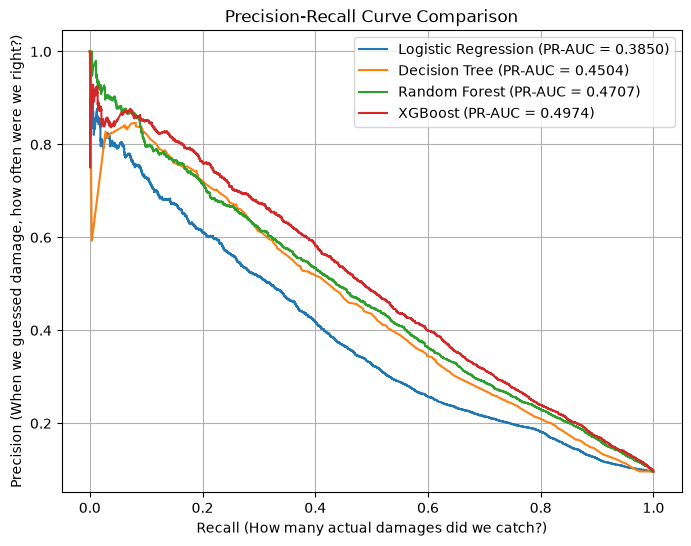

In [5]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    p, r, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(r, p)
    plt.plot(r, p, label=f'{name} (PR-AUC = {pr_auc:.4f})')

plt.xlabel('Recall (How many actual damages did we catch?)')
plt.ylabel('Precision (When we guessed damage, how often were we right?)')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import joblib

# Save the best model
model_path = r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\models\xgboost_model.pkl"
joblib.dump(xgb, model_path)

print(" XGBoost model saved successfully!")

 XGBoost model saved successfully!


C:\Users\sushm\AppData\Local\Temp\ipykernel_26040\2106717946.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')


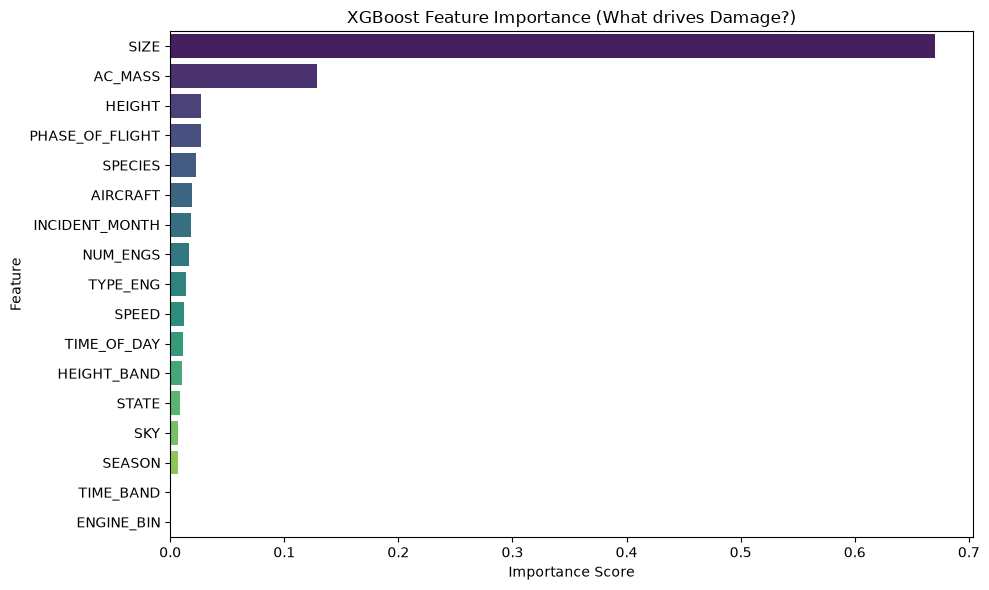

=== TOP 5 FEATURES DRIVING DAMAGE ===
        Feature  Importance
           SIZE    0.670363
        AC_MASS    0.128580
         HEIGHT    0.027363
PHASE_OF_FLIGHT    0.026767
        SPECIES    0.022531


In [7]:
# Get feature importances from XGBoost
importances = xgb.feature_importances_
feature_names = X_train.columns

# Create a dataframe for plotting
feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
plt.title('XGBoost Feature Importance (What drives Damage?)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Print the top 5 features
print("=== TOP 5 FEATURES DRIVING DAMAGE ===")
print(feat_df.head(5).to_string(index=False))

In [8]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

print("Starting Hyperparameter Tuning (Random Forest)...")
start_time = time.time()

# Define a SMALL grid (don't make it too big or it will take forever)
param_grid = {
    'n_estimators': [50, 100],        # Number of trees
    'max_depth': [10, 15, 20],        # How deep each tree can go
    'min_samples_leaf': [10, 20]      # Minimum samples at a leaf (prevents overfitting)
}

# We use StratifiedKFold to keep the 90/10 class ratio in every fold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',  # We optimize for F1-score because of the imbalance
    n_jobs=-1,
    verbose=1
)

# Fit it (This trains 2 x 3 x 2 = 12 models)
grid_search.fit(X_train, y_train)

print(f"\n✅ Tuning finished in {time.time() - start_time:.2f} seconds")
print("Best Hyperparameters found:")
print(grid_search.best_params_)
print(f"Best F1-Score on validation: {grid_search.best_score_:.4f}")

# Save the best tuned model
best_rf_tuned = grid_search.best_estimator_

Starting Hyperparameter Tuning (Random Forest)...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

✅ Tuning finished in 139.79 seconds
Best Hyperparameters found:
{'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 50}
Best F1-Score on validation: 0.4267


In [9]:
# Evaluate the tuned Random Forest
y_pred_tuned = best_rf_tuned.predict(X_test)
y_prob_tuned = best_rf_tuned.predict_proba(X_test)[:, 1]

precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)

p, r, _ = precision_recall_curve(y_test, y_prob_tuned)
pr_auc_tuned = auc(r, p)

print("=== TUNED RANDOM FOREST ===")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall:    {recall_tuned:.4f}")
print(f"F1-Score:  {f1_tuned:.4f}")
print(f"PR-AUC:    {pr_auc_tuned:.4f}")

# Compare to XGBoost (the previous winner)
print("\n=== VS XGBOOST (BASELINE WINNER) ===")
print(f"XGBoost PR-AUC: 0.4974")
print(f"Tuned RF PR-AUC: {pr_auc_tuned:.4f}")

=== TUNED RANDOM FOREST ===
Precision: 0.3008
Recall:    0.7042
F1-Score:  0.4215
PR-AUC:    0.4864

=== VS XGBOOST (BASELINE WINNER) ===
XGBoost PR-AUC: 0.4974
Tuned RF PR-AUC: 0.4864


We tuned the Random Forest using GridSearchCV, but it still couldn't beat XGBoost. This proves that the ensemble method matters more than the hyperparameters in this dataset. XGBoost's boosting architecture handles the 90/10 class imbalance much better than bagging.

In [12]:
import joblib

# 1. Define paths
model_dir = r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\models"

# 2. Save the model and the list of features
joblib.dump(xgb, f"{model_dir}\\best_model.pkl")
joblib.dump(feature_cols, f"{model_dir}\\feature_cols.pkl")

print("✅ Model and features saved successfully!")
print("We don't need encoders.pkl for this dashboard version.")

✅ Model and features saved successfully!
We don't need encoders.pkl for this dashboard version.


In [13]:
import joblib
model_dir = r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\models"
joblib.dump(xgb, f"{model_dir}\\best_model.pkl")
joblib.dump(feature_cols, f"{model_dir}\\feature_cols.pkl")
print("✅ Model saved!")

✅ Model saved!
